# 02 Dataset Visualization

## Objective
Visualize the dataset to understand class distributions, sample images per crop category, image dimensions, and prepare label mappings for training.

**Prerequisites:** `01_data_check.ipynb`
**Next Step:** `03_targeted_augmentation.ipynb`

### Import Libraries

In [37]:
import cv2
import numpy as np

print(cv2.__version__)
print(np.__version__)

4.10.0
1.26.4


In [38]:
try:
    import numpy
    print("✓ NumPy:", numpy.__version__)
except ImportError as e:
    print("✗ NumPy failed:", e)
    
try:
    import matplotlib
    print("✓ Matplotlib:", matplotlib.__version__)
except ImportError as e:
    print("✗ Matplotlib failed:", e)

try:
    import pandas
    print("✓ Pandas:", pandas.__version__)
except ImportError as e:
    print("✗ Pandas failed:", e)


✓ NumPy: 1.26.4
✓ Matplotlib: 3.8.4
✓ Pandas: 2.2.2


In [39]:
import sys
import os

sys.path.insert(0, '../utils')

from data_utils import (
    verify_dataset_structure,
    get_image_files,
    load_image
)
from visualization_utils import (
    plot_sample_images,
    plot_class_distribution,
    plot_crop_disease_breakdown
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from PIL import Image
import cv2

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Set matplotlib style
plt.style.use('seaborn-v0_8-darkgrid')

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


### Setup

In [40]:
DATASET_PATH = '../Final_images_phd'

print(f"Dataset path: {DATASET_PATH}")
print(f"Path exists: {os.path.exists(DATASET_PATH)}")

# Load dataset statistics
stats = verify_dataset_structure(DATASET_PATH)
print(f"\n✓ Dataset loaded: {stats['total_images']} images found")

Dataset path: ../Final_images_phd
Path exists: True

✓ Dataset loaded: 761 images found


### 1. Overall Class Distribution

Total Classes: 40
Total Images: 761


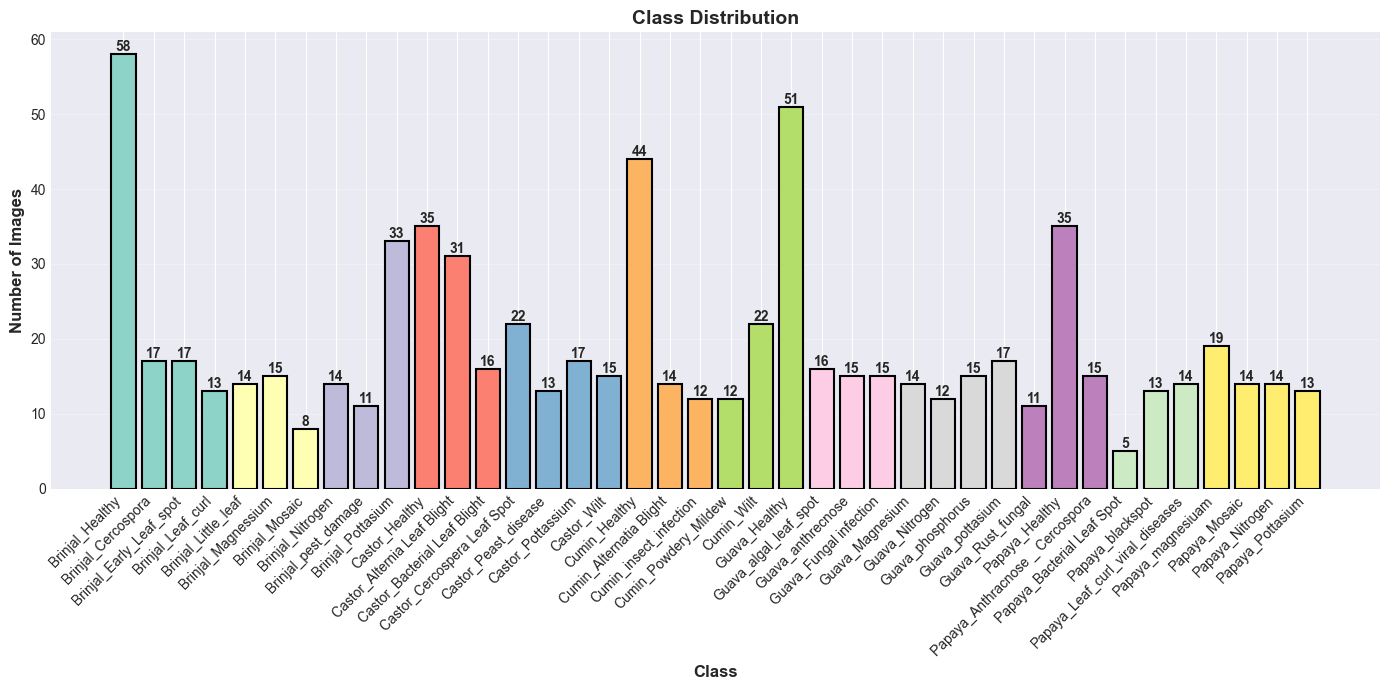

✓ Saved: class_distribution.png


<Figure size 640x480 with 0 Axes>

In [41]:
# Get all classes and counts
class_counts = {}
for crop, data in stats['crops'].items():
    class_counts[f"{crop}_Healthy"] = data['healthy']
    for disease, count in data['unhealthy'].items():
        class_counts[f"{crop}_{disease}"] = count

print(f"Total Classes: {len(class_counts)}")
print(f"Total Images: {sum(class_counts.values())}")

# Plot distribution
plot_class_distribution(class_counts, figsize=(14, 7))
plt.savefig('../results/plots/class_distribution.png', dpi=300, bbox_inches='tight')
print("✓ Saved: class_distribution.png")

### 2. Disease Breakdown by Crop (Pie Charts)

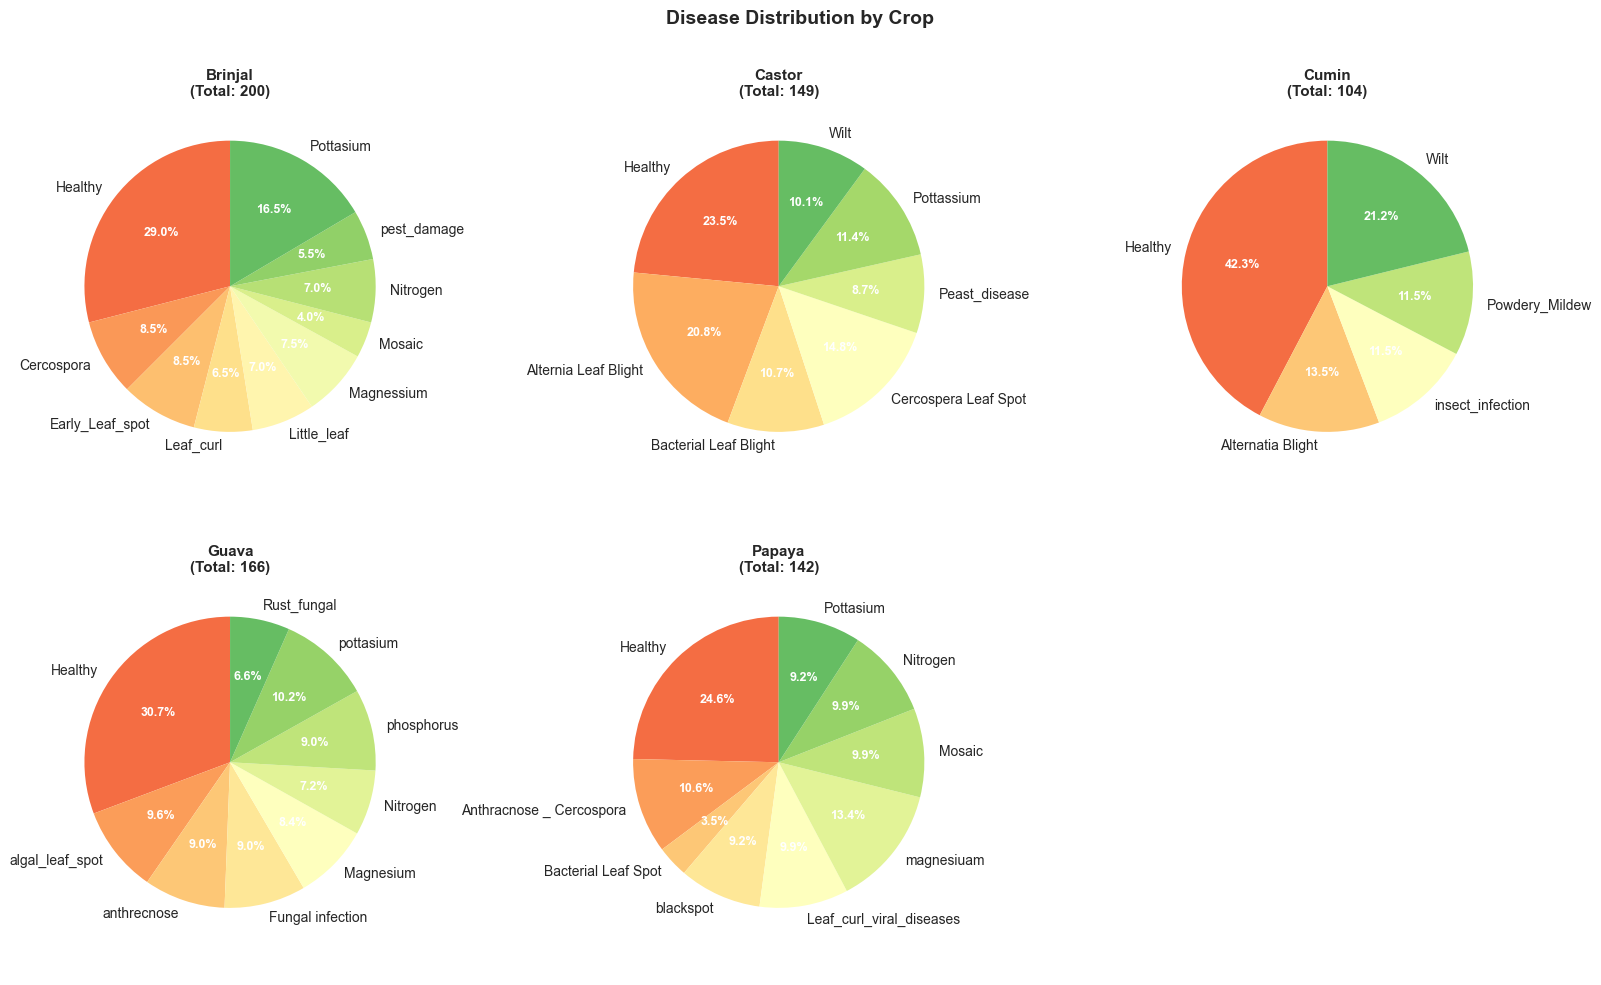

✓ Saved: crop_disease_breakdown.png


<Figure size 640x480 with 0 Axes>

In [42]:
plot_crop_disease_breakdown(stats, figsize=(16, 10))
plt.savefig('../results/plots/crop_disease_breakdown.png', dpi=300, bbox_inches='tight')
print("✓ Saved: crop_disease_breakdown.png")

### 3. Sample Images from Each Crop (Healthy)

Loading healthy sample images from each crop...



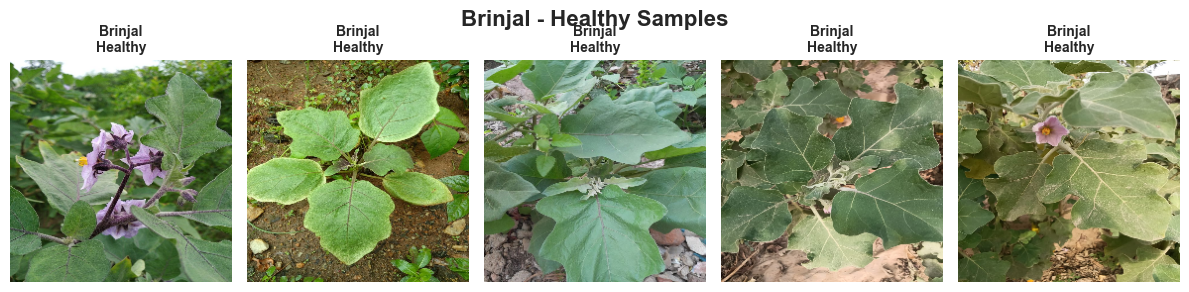

✓ Brinjal: 5 healthy samples displayed


<Figure size 640x480 with 0 Axes>

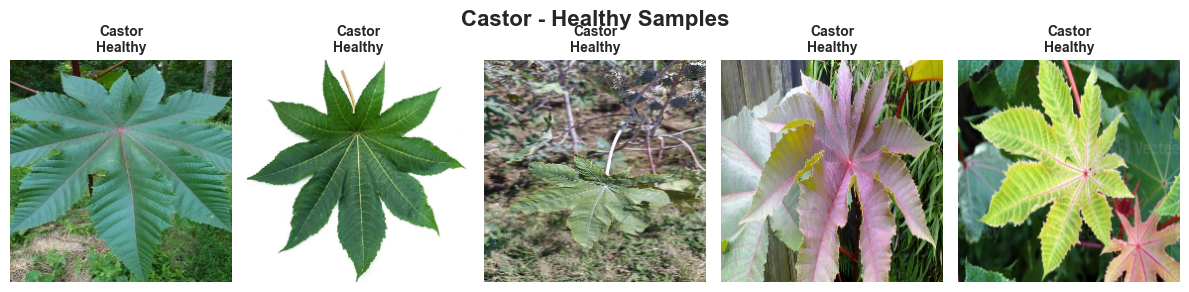

✓ Castor: 5 healthy samples displayed


<Figure size 640x480 with 0 Axes>

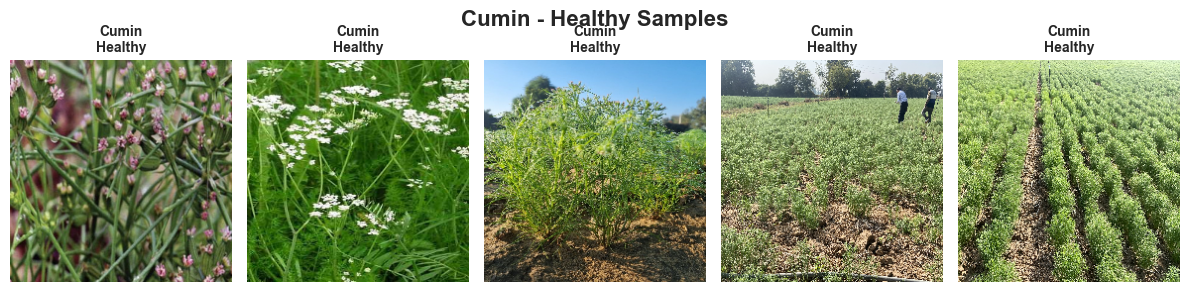

✓ Cumin: 5 healthy samples displayed


<Figure size 640x480 with 0 Axes>

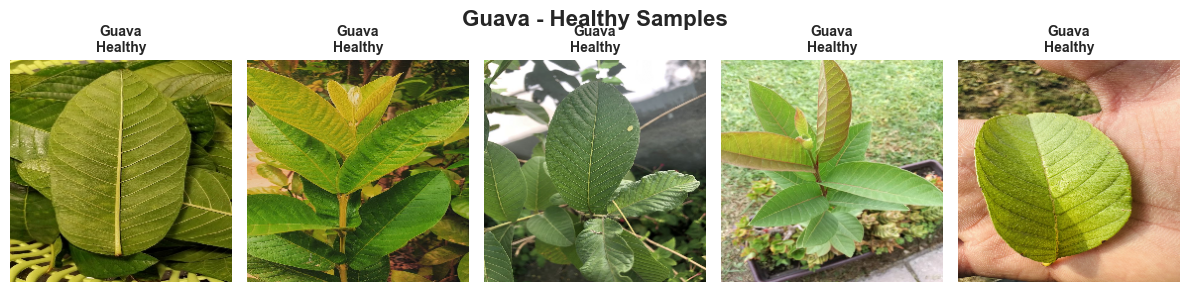

✓ Guava: 5 healthy samples displayed


<Figure size 640x480 with 0 Axes>

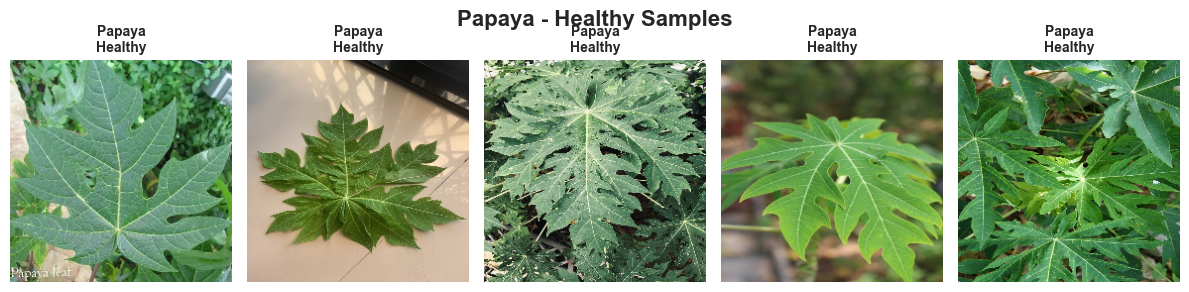

✓ Papaya: 5 healthy samples displayed


<Figure size 640x480 with 0 Axes>

In [43]:
print("Loading healthy sample images from each crop...\n")

for crop in sorted(stats['crops'].keys()):
    crop_path = os.path.join(DATASET_PATH, crop)
    
    # Find healthy folder
    healthy_path = None
    for item in os.listdir(crop_path):
        if 'healthy' in item.lower() and os.path.isdir(os.path.join(crop_path, item)):
            healthy_path = os.path.join(crop_path, item)
            break
    
    if healthy_path and os.path.exists(healthy_path):
        images_list = get_image_files(healthy_path)
        if images_list:
            # Load samples
            sample_paths = images_list[:5]  # Get first 5
            sample_images = []
            sample_labels = []
            
            for img_path in sample_paths:
                img = load_image(img_path, target_size=(224, 224))
                if img is not None:
                    sample_images.append(img)
                    sample_labels.append(f"{crop}\nHealthy")
            
            if sample_images:
                plot_sample_images(np.array(sample_images), sample_labels, 
                                   title=f"{crop} - Healthy Samples", figsize=(12, 3))
                plt.savefig(f'../results/plots/{crop}_healthy_samples.png', dpi=300, bbox_inches='tight')
                print(f"✓ {crop}: {len(sample_images)} healthy samples displayed")

### 4. Sample Images from Diseases (Unhealthy)

Loading disease sample images...



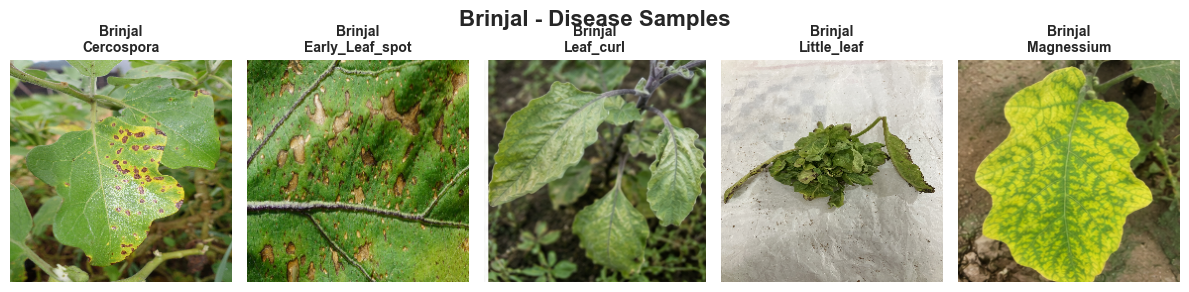

✓ Brinjal: 5 disease samples displayed


<Figure size 640x480 with 0 Axes>

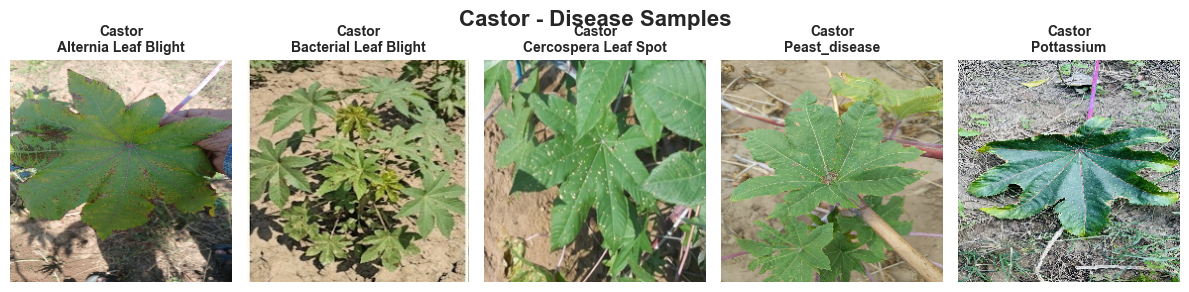

✓ Castor: 5 disease samples displayed


<Figure size 640x480 with 0 Axes>

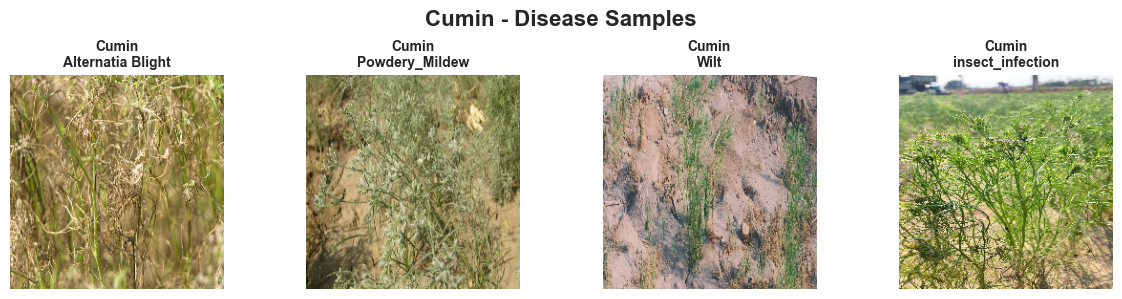

✓ Cumin: 4 disease samples displayed


<Figure size 640x480 with 0 Axes>

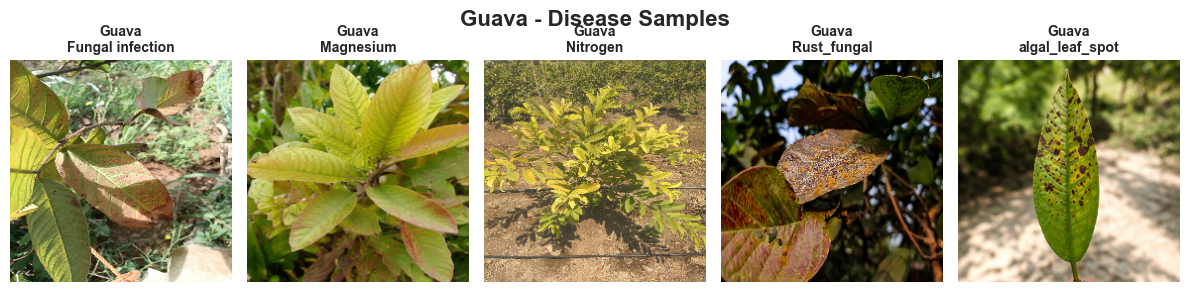

✓ Guava: 5 disease samples displayed


<Figure size 640x480 with 0 Axes>

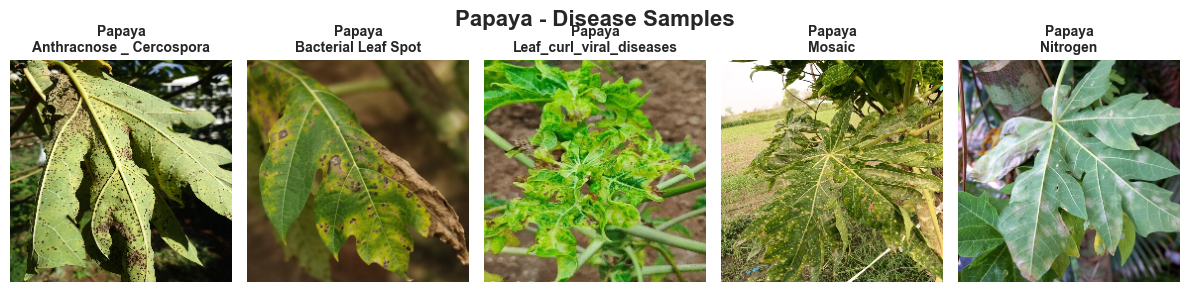

✓ Papaya: 5 disease samples displayed


<Figure size 640x480 with 0 Axes>

In [44]:
print("Loading disease sample images...\n")

for crop in sorted(stats['crops'].keys()):
    crop_path = os.path.join(DATASET_PATH, crop)
    
    # Find unhealthy folder
    unhealthy_path = None
    for item in os.listdir(crop_path):
        if 'unhealthy' in item.lower() and os.path.isdir(os.path.join(crop_path, item)):
            unhealthy_path = os.path.join(crop_path, item)
            break
    
    if unhealthy_path and os.path.exists(unhealthy_path):
        diseases = os.listdir(unhealthy_path)
        sample_images = []
        sample_labels = []
        
        # Get one sample from each disease
        for disease in sorted(diseases)[:5]:  # Limit to 5 diseases
            disease_path = os.path.join(unhealthy_path, disease)
            if os.path.isdir(disease_path):
                images_list = get_image_files(disease_path)
                if images_list:
                    img_path = images_list[0]
                    img = load_image(img_path, target_size=(224, 224))
                    if img is not None:
                        sample_images.append(img)
                        sample_labels.append(f"{crop}\n{disease}")
        
        if sample_images:
            plot_sample_images(np.array(sample_images), sample_labels, 
                               title=f"{crop} - Disease Samples", figsize=(12, 3))
            plt.savefig(f'../results/plots/{crop}_disease_samples.png', dpi=300, bbox_inches='tight')
            print(f"✓ {crop}: {len(sample_images)} disease samples displayed")

### 5. Image Dimension Analysis

In [45]:
print("Analyzing image dimensions...\n")

dimensions = []
sizes_mb = []
sample_size = 100  # Sample 100 random images

# Get all image paths
all_images = []
for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_images.append(os.path.join(root, file))

# Sample random images
sampled_images = random.sample(all_images, min(sample_size, len(all_images)))

for img_path in sampled_images:
    try:
        img = Image.open(img_path)
        width, height = img.size
        dimensions.append((height, width))
        
        # Get file size
        size_mb = os.path.getsize(img_path) / (1024 * 1024)
        sizes_mb.append(size_mb)
    except Exception as e:
        pass

# Analyze dimensions
heights = [d[0] for d in dimensions]
widths = [d[1] for d in dimensions]

print("Image Dimensions Statistics:")
print(f"  Height - Min: {min(heights)}, Max: {max(heights)}, Mean: {np.mean(heights):.1f}")
print(f"  Width  - Min: {min(widths)}, Max: {max(widths)}, Mean: {np.mean(widths):.1f}")
print(f"\nImage Size Statistics:")
print(f"  Min: {min(sizes_mb):.3f} MB")
print(f"  Max: {max(sizes_mb):.3f} MB")
print(f"  Mean: {np.mean(sizes_mb):.3f} MB")
print(f"  Total: {sum(sizes_mb):.2f} MB (for {len(sampled_images)} samples)")

Analyzing image dimensions...

Image Dimensions Statistics:
  Height - Min: 186, Max: 4608, Mean: 1726.0
  Width  - Min: 178, Max: 4608, Mean: 1475.8

Image Size Statistics:
  Min: 0.014 MB
  Max: 7.816 MB
  Mean: 1.136 MB
  Total: 113.59 MB (for 100 samples)


### 6. Plot Dimension Distribution

✓ Saved: image_dimensions.png


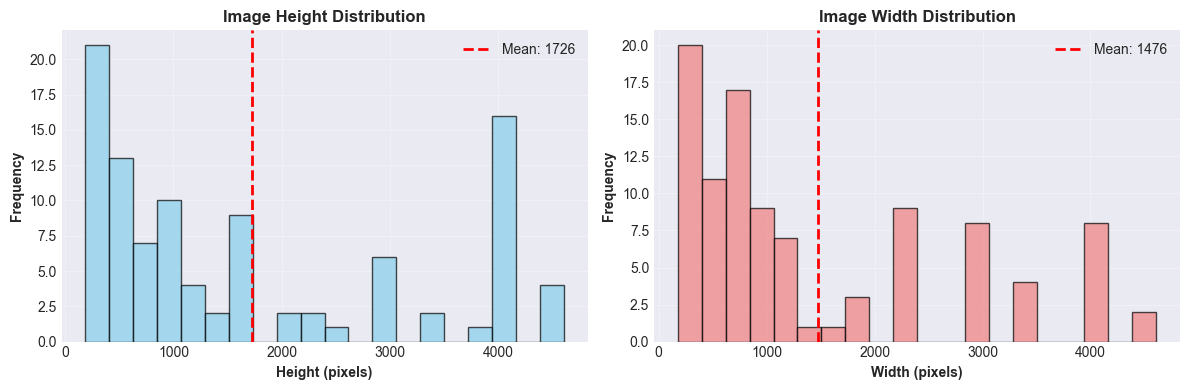

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Height distribution
axes[0].hist(heights, bins=20, edgecolor='black', alpha=0.7, color='skyblue')
axes[0].axvline(np.mean(heights), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(heights):.0f}')
axes[0].set_xlabel('Height (pixels)', fontweight='bold')
axes[0].set_ylabel('Frequency', fontweight='bold')
axes[0].set_title('Image Height Distribution', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Width distribution
axes[1].hist(widths, bins=20, edgecolor='black', alpha=0.7, color='lightcoral')
axes[1].axvline(np.mean(widths), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(widths):.0f}')
axes[1].set_xlabel('Width (pixels)', fontweight='bold')
axes[1].set_ylabel('Frequency', fontweight='bold')
axes[1].set_title('Image Width Distribution', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/plots/image_dimensions.png', dpi=300, bbox_inches='tight')
print("✓ Saved: image_dimensions.png")
plt.show()

### 7. Create Class Label Mapping

In [47]:
import json

# Create label encoding
label_encoding = {}
reverse_encoding = {}
label_idx = 0

for crop in sorted(stats['crops'].keys()):
    data = stats['crops'][crop]
    
    # Healthy class
    if data['healthy'] > 0:
        label_name = f"{crop}_Healthy"
        label_encoding[label_name] = label_idx
        reverse_encoding[label_idx] = label_name
        label_idx += 1
    
    # Disease classes
    for disease in sorted(data['unhealthy'].keys()):
        label_name = f"{crop}_{disease}"
        label_encoding[label_name] = label_idx
        reverse_encoding[label_idx] = label_name
        label_idx += 1

print(f"\nTotal Classes: {len(label_encoding)}\n")
print("Class Label Mapping:")
for label, idx in sorted(label_encoding.items(), key=lambda x: x[1]):
    print(f"  {idx:2d} -> {label}")

# Save mapping
os.makedirs('../results/reports', exist_ok=True)
mapping_path = '../results/reports/label_encoding.json'
with open(mapping_path, 'w') as f:
    json.dump({'label_encoding': label_encoding, 'reverse_encoding': {int(k): v for k, v in reverse_encoding.items()}}, f, indent=4)

print(f"\n✓ Label mapping saved to: {mapping_path}")


Total Classes: 40

Class Label Mapping:
   0 -> Brinjal_Healthy
   1 -> Brinjal_Cercospora
   2 -> Brinjal_Early_Leaf_spot
   3 -> Brinjal_Leaf_curl
   4 -> Brinjal_Little_leaf
   5 -> Brinjal_Magnessium
   6 -> Brinjal_Mosaic
   7 -> Brinjal_Nitrogen
   8 -> Brinjal_Pottasium
   9 -> Brinjal_pest_damage
  10 -> Castor_Healthy
  11 -> Castor_Alternia Leaf Blight
  12 -> Castor_Bacterial Leaf Blight
  13 -> Castor_Cercospera Leaf Spot
  14 -> Castor_Peast_disease
  15 -> Castor_Pottassium
  16 -> Castor_Wilt
  17 -> Cumin_Healthy
  18 -> Cumin_Alternatia Blight
  19 -> Cumin_Powdery_Mildew
  20 -> Cumin_Wilt
  21 -> Cumin_insect_infection
  22 -> Guava_Healthy
  23 -> Guava_Fungal infection
  24 -> Guava_Magnesium
  25 -> Guava_Nitrogen
  26 -> Guava_Rust_fungal
  27 -> Guava_algal_leaf_spot
  28 -> Guava_anthrecnose
  29 -> Guava_phosphorus
  30 -> Guava_pottasium
  31 -> Papaya_Healthy
  32 -> Papaya_Anthracnose _ Cercospora
  33 -> Papaya_Bacterial Leaf Spot
  34 -> Papaya_Leaf_curl

### 8. Summary Statistics

In [48]:
print("\n" + "="*70)
print("VISUALIZATION SUMMARY")
print("="*70)

print(f"\n📊 Dataset Overview:")
print(f"  Total Images: {stats['total_images']}")
print(f"  Total Classes: {len(label_encoding)}")
print(f"  Total Crops: {len(stats['crops'])}")

print(f"\n📷 Image Statistics:")
print(f"  Sample Size Analyzed: {len(sampled_images)} images")
print(f"  Height Range: {min(heights)} - {max(heights)} pixels")
print(f"  Width Range: {min(widths)} - {max(widths)} pixels")
print(f"  Recommended Input Size: 224 x 224")

print(f"\n💾 Storage:")
print(f"  Total Size (estimated): {sum(sizes_mb) * len(all_images) / len(sampled_images) / 1024:.2f} GB")

print(f"\n✓ Visualizations saved to: ../results/plots/")
print(f"✓ Label mapping saved")
print(f"\n→ Next Step: 03_targeted_augmentation.ipynb")



VISUALIZATION SUMMARY

📊 Dataset Overview:
  Total Images: 761
  Total Classes: 40
  Total Crops: 5

📷 Image Statistics:
  Sample Size Analyzed: 100 images
  Height Range: 186 - 4608 pixels
  Width Range: 178 - 4608 pixels
  Recommended Input Size: 224 x 224

💾 Storage:
  Total Size (estimated): 0.85 GB

✓ Visualizations saved to: ../results/plots/
✓ Label mapping saved

→ Next Step: 03_data_preprocessing.ipynb
